# OOB errors for random forests: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/ensemble/plot_ensemble_oob.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/ensemble/plot_ensemble_oob.html)).

**Scenario:** three `RandomForestClassifier(warm_start=True, oob_score=True, random_state=123)` models with
`max_features` set to `"sqrt"`, `"log2"` and `None` grow from 15 to 150 trees in steps of 5 on
`make_classification(n_samples=500, n_features=25, n_informative=15, ...)`. After every warm-start fit the
OOB error `1 - oob_score_` is recorded and plotted against `n_estimators`.

**Adaptations**
- None to the data or the parameters. The dataset is generated in Python and shared with Mojo.
- Moxie forests take Float32 feature matrices and Float64 targets. scikit-learn's forests cast `X` to
  float32 internally, so both sides train on identical values; the 0/1 labels are shared as Float64.
- `max_features` string/None values use Moxie's typed `FeatureCount` variant.
- `plt.show()` is replaced by a small paired figure (dpi 80).
- Extra checks beyond the plot: the final forests' `oob_decision_function_`, `feature_importances_` and
  `predict_proba` on the training data.

**Determinism:** deterministic. Every forest has an integer `random_state`; warm starts replay the seeds a
cold fit would have drawn, in scikit-learn and in Moxie. The OOB curves must therefore match exactly.
The reference runs on the installed scikit-learn wheel of the notebooks environment (1.9.1); its forest
sampling code is unchanged relative to the pinned revision for these settings (the family parity runs against
the pinned source build).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("ensemble/plot_ensemble_oob")

## 1. scikit-learn (Python reference)

The official example code; only `plt.show()` is deferred to the side-by-side plot.

In [2]:
from collections import OrderedDict

import matplotlib.pyplot as plt
import numpy as np

from sklearn.datasets import make_classification
from sklearn.ensemble import RandomForestClassifier

RANDOM_STATE = 123

# Generate a binary classification dataset.
X, y = make_classification(
    n_samples=500,
    n_features=25,
    n_clusters_per_class=1,
    n_informative=15,
    random_state=RANDOM_STATE,
)

# NOTE: Setting the `warm_start` construction parameter to `True` disables
# support for parallelized ensembles but is necessary for tracking the OOB
# error trajectory during training.
ensemble_clfs = [
    (
        "RandomForestClassifier, max_features='sqrt'",
        RandomForestClassifier(
            warm_start=True,
            oob_score=True,
            max_features="sqrt",
            random_state=RANDOM_STATE,
        ),
    ),
    (
        "RandomForestClassifier, max_features='log2'",
        RandomForestClassifier(
            warm_start=True,
            max_features="log2",
            oob_score=True,
            random_state=RANDOM_STATE,
        ),
    ),
    (
        "RandomForestClassifier, max_features=None",
        RandomForestClassifier(
            warm_start=True,
            max_features=None,
            oob_score=True,
            random_state=RANDOM_STATE,
        ),
    ),
]

# Map a classifier name to a list of (<n_estimators>, <error rate>) pairs.
error_rate = OrderedDict((label, []) for label, _ in ensemble_clfs)

# Range of `n_estimators` values to explore.
min_estimators = 15
max_estimators = 150

for label, clf in ensemble_clfs:
    for i in range(min_estimators, max_estimators + 1, 5):
        clf.set_params(n_estimators=i)
        clf.fit(X, y)

        # Record the OOB error for each `n_estimators=i` setting.
        oob_error = 1 - clf.oob_score_
        error_rate[label].append((i, oob_error))

sk_errors = np.array([[e for _, e in error_rate[label]] for label, _ in ensemble_clfs])
sk_oobd = np.stack([clf.oob_decision_function_ for _, clf in ensemble_clfs])
sk_imp = np.stack([clf.feature_importances_ for _, clf in ensemble_clfs])
sk_proba = np.stack([clf.predict_proba(X) for _, clf in ensemble_clfs])
sk_len = np.array([len(clf.estimators_) for _, clf in ensemble_clfs])
print("sklearn final OOB errors:", sk_errors[:, -1])
nb.share(X=X, y=y.astype(np.float64))

sklearn final OOB errors: [0.054 0.064 0.08 ]


## 2. Moxie (native Mojo)

The same warm-start loop through `moxie.ensemble.RandomForestClassifier`: `set_params(n_estimators=i)` then
`fit` adds five trees per step and recomputes the OOB score.

In [3]:
%%mojo oob_curves
from moxie.ensemble import RandomForestClassifier
from moxie.tree._classes import FeatureCount
from moxie_nb_io import load, save, save_floats, save_ints
import numojo as nm


def main() raises:
    var X = load[DType.float32]("X")
    var y = load("y")
    var settings = List[FeatureCount]()
    settings.append(FeatureCount(String("sqrt")))
    settings.append(FeatureCount(String("log2")))
    settings.append(FeatureCount(NoneType()))
    var names: List[String] = ["sqrt", "log2", "None"]
    var lengths = List[Int]()
    for s in range(3):
        var clf = RandomForestClassifier(warm_start=True, oob_score=True,
            max_features=settings[s].copy(), random_state=123)
        var errors = List[Float64]()
        for i in range(15, 151, 5):
            _ = clf.set_params(n_estimators=i)
            _ = clf.fit(X, y)
            errors.append(1 - clf.oob_score_)
        save_floats("errors_" + String(s), errors)
        save("oobd_" + String(s), clf.oob_decision_function_)
        save("imp_" + String(s), clf.feature_importances_)
        save("proba_" + String(s), clf.predict_proba(X))
        lengths.append(len(clf))
        print("max_features=" + names[s], "final OOB error:", errors[len(errors) - 1], "trees:", len(clf))
    save_ints("lengths", lengths)

max_features=sqrt final OOB error: 0.05400000000000005 trees: 150
max_features=log2 final OOB error: 0.06399999999999995 trees: 150
max_features=None final OOB error: 0.07999999999999996 trees: 150


## 3. Side by side and parity

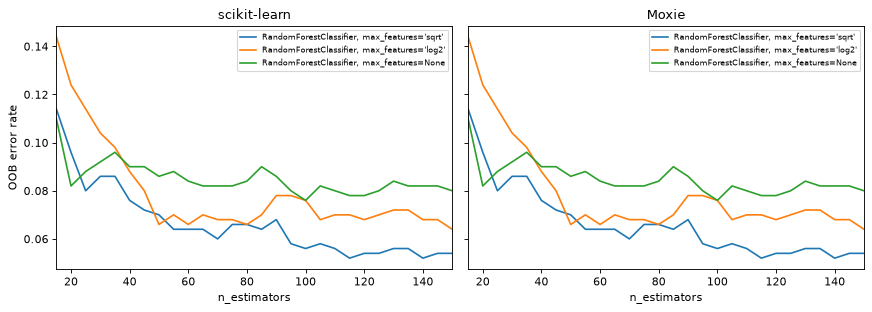

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
OOB error curves (3 x 28 warm-start fits),PASS,"(3, 28)","(3, 28)",,,exact,0 mismatches,
len(estimators_),PASS,"(3,)","(3,)",,,exact,0 mismatches,
oob_decision_function_ (150 trees),PASS,"(3, 500, 2)","(3, 500, 2)",,,exact,0 mismatches,
predict_proba(X) (150 trees),PASS,"(3, 500, 2)","(3, 500, 2)",,,exact,0 mismatches,
feature_importances_,PASS,"(3, 25)","(3, 25)",5.55e-17,3.76e-16,"rtol=1e-12, atol=1e-15",,"identical trees; impurity decreases are accumulated and normalized in a different order than scikit-learn's Cython, which leaves last-ulp differences"


In [4]:
mx = nb.results["oob_curves"]
mx_errors = np.stack([mx[f"errors_{s}"] for s in range(3)])
xs = list(range(min_estimators, max_estimators + 1, 5))
fig, axes = plt.subplots(1, 2, figsize=(11, 4), dpi=80, sharey=True)
for ax, errors, title in ((axes[0], sk_errors, "scikit-learn"), (axes[1], mx_errors, "Moxie")):
    for (label, _), curve in zip(ensemble_clfs, errors):
        ax.plot(xs, curve, label=label)
    ax.set_xlim(min_estimators, max_estimators)
    ax.set_xlabel("n_estimators"); ax.set_title(title)
    ax.legend(loc="upper right", fontsize=7)
axes[0].set_ylabel("OOB error rate")
plt.tight_layout()
plt.show()

moxie_nb.side_by_side(sklearn=sk_errors[:, -5:], moxie=mx_errors[:, -5:])
nb.compare("OOB error curves (3 x 28 warm-start fits)", sk_errors, mx_errors, exact=True)
nb.compare("len(estimators_)", sk_len, mx["lengths"], exact=True)
nb.compare("oob_decision_function_ (150 trees)", sk_oobd, np.stack([mx[f"oobd_{s}"] for s in range(3)]),
           exact=True)
nb.compare("predict_proba(X) (150 trees)", sk_proba, np.stack([mx[f"proba_{s}"] for s in range(3)]),
           exact=True)
nb.compare("feature_importances_", sk_imp, np.stack([mx[f"imp_{s}"] for s in range(3)]), rtol=1e-12, atol=1e-15,
           reason="identical trees; impurity decreases are accumulated and normalized in a different order "
                  "than scikit-learn's Cython, which leaves last-ulp differences")
nb.report()
nb.assert_parity()